# Mean Embedding Classifier for IMDb sentiment classification

This notebook analyzes the performace of a Mean Embedding Classifier: it takes the sequences encoded via the vocabulary, creates embeddings for each token using `nn.Embeddings`, then averages the embedding vectors for each sequence and produces logits with a last `nn.Linear` layer.

## 1. Imports and project paths

The path setup below searches the current directory and its parents for the project-level `src` folder. This lets the notebook be run from a `notebooks/` directory or the project root.

In [30]:
import sys
from functools import partial
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, random_split

# Find the project root (the directory containing src/).
current_dir = Path.cwd()
project_root = next(
    (path for path in [current_dir, *current_dir.parents] if (path / "src").is_dir()),
    None
)

if project_root is None:
    raise FileNotFoundError("Could not find the project root containing the 'src' directory.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

DATA_ROOT = project_root / "data" / "aclImdb"
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"IMDb dataset directory not found: {DATA_ROOT}")

## 2. Load the IMDb dataset

The dataset returns raw review text and an integer label (`1` for positive, `0` for negative). We keep the official test set separate and split the official training set into training and validation subsets.

In [31]:
from src.data.dataset import IMDbDataset
from src.data.tokenizer import WhitespaceTokenizer
from src.data.vocabulary import Vocabulary
from src.models.linear import LinearModel, LinearWithReluModel

train_dataset = IMDbDataset(DATA_ROOT, train=True)
test_dataset = IMDbDataset(DATA_ROOT, train=False)

print(f"Training examples available: {len(train_dataset)}")
print(f"Test examples: {len(test_dataset)}")

# Reserve 10% of the original training data for validation.
train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size

generator = torch.Generator().manual_seed(42)
train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

print(f"Training subset: {len(train_subset)}")
print(f"Validation subset: {len(val_subset)}")

Training examples available: 25000
Test examples: 25000
Training subset: 22500
Validation subset: 2500


## 3. Build the vocabulary and DataLoaders

The vocabulary is built **only from the training subset**. This avoids using validation or test text when deciding which tokens belong to the vocabulary.

The vocabulary maps each token to an integer ID. Those IDs are useful for lookup, but they are not meaningful numerical features by themselves.

In [32]:
tokenizer = WhitespaceTokenizer()
vocab = Vocabulary(tokenizer, min_freq=2)
vocab.build([review for review, _ in train_subset])

print(f"Vocabulary size (including special tokens): {len(vocab)}")

Vocabulary size (including special tokens): 102801


In [33]:
from src.data.preprocessing import collate_fn

collate = partial(collate_fn, vocab=vocab)

train_loader = DataLoader(
    train_subset,
    batch_size=32,
    shuffle=True,
    collate_fn=collate
)

val_loader = DataLoader(
    val_subset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate
)

## 4. Define the model

The final layer returns raw logits; do not add Softmax when training with `CrossEntropyLoss`.

In [34]:
from src.models.MeanEmbeddingClassifier import MeanEmbeddingClassifier

model = MeanEmbeddingClassifier(
    input_dim=len(vocab), 
    embedding_dim=100, 
    output_dim=2
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## 5. Train and Evaluate the Classifier

In [35]:
num_epochs = 10
train_losses = []
val_losses = []
best_val_loss = float("inf")

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0.0

    for inputs, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = correct / total

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss

        torch.save(
            model.state_dict(),
            "best_mean_embedding_model.pth"
        )

        print("Best model saved!")

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Best model saved!
Epoch 1/10 | Train Loss: 0.5889 | Val Loss: 0.4666 | Val Accuracy: 0.8184
Best model saved!
Epoch 2/10 | Train Loss: 0.3540 | Val Loss: 0.3562 | Val Accuracy: 0.8632
Best model saved!
Epoch 3/10 | Train Loss: 0.2397 | Val Loss: 0.3188 | Val Accuracy: 0.8840
Best model saved!
Epoch 4/10 | Train Loss: 0.1711 | Val Loss: 0.3028 | Val Accuracy: 0.8936
Best model saved!
Epoch 5/10 | Train Loss: 0.1218 | Val Loss: 0.2994 | Val Accuracy: 0.8952
Epoch 6/10 | Train Loss: 0.0848 | Val Loss: 0.3022 | Val Accuracy: 0.8984
Epoch 7/10 | Train Loss: 0.0578 | Val Loss: 0.3095 | Val Accuracy: 0.8984
Epoch 8/10 | Train Loss: 0.0387 | Val Loss: 0.3207 | Val Accuracy: 0.8956
Epoch 9/10 | Train Loss: 0.0254 | Val Loss: 0.3330 | Val Accuracy: 0.8948
Epoch 10/10 | Train Loss: 0.0166 | Val Loss: 0.3481 | Val Accuracy: 0.8940


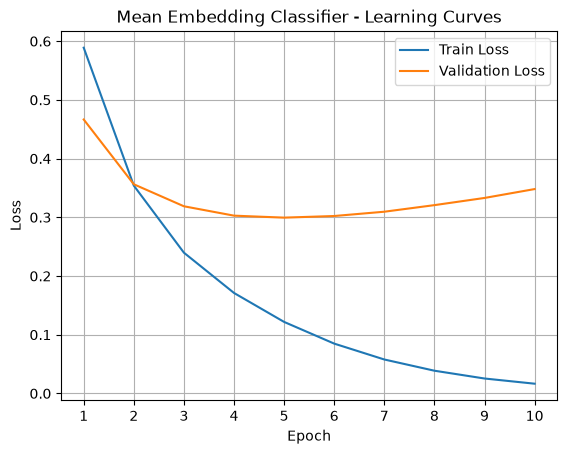

In [36]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Mean Embedding Classifier - Learning Curves")
plt.legend()
plt.xticks(epochs)
plt.grid(True)
plt.show()

With just 5 epochs it does not go into overfitting, but trying with 10 it does.
The Mean Embedding Classifier has similar performances to the BoW one (Bag of Words), this might be due to the fact that it is yes learning dense representations for the token, but it still discards the order of the tokens since it uses the average of the embedding vectors to predict

## 6. Load the best model
We load the best model based on which obtained the lowest validation loss across the epochs

In [38]:
model.load_state_dict(
    torch.load("best_mean_embedding_model.pth", map_location="cpu")
)

<All keys matched successfully>

## 7. Test the model on the test set

In [39]:
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate
)


test_loss = 0.0
correct = 0
total = 0

model.eval()

with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

avg_test_loss = test_loss / len(test_loader)
test_accuracy = correct / total

print(f"Test Loss: {avg_test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.2993
Test Accuracy: 0.8762
